In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import glob
import os

## Load Noise Measurements

Load all CSV files from the noise_testing directory. Add your measurement files here.

In [11]:
# Load all noise measurement files
noise_files = glob.glob("PE_static_noise_20251202_1*.csv")
noise_files.sort()

print(f"Found {len(noise_files)} noise measurement files:")
for f in noise_files:
    print(f"  - {f}")

# Load data into dictionary
noise_data = {}
for file in noise_files:
    label = file.replace('PE_static_noise_', '').replace('.csv', '')
    noise_data[label] = pd.read_csv(file)
    print(f"Loaded {label}: {len(noise_data[label])} samples")

Found 13 noise measurement files:
  - PE_static_noise_20251202_175116_sin_3d.csv
  - PE_static_noise_20251202_175152_con_3d.csv
  - PE_static_noise_20251202_175353_stale_3d.csv
  - PE_static_noise_20251202_175741_sin_nada.csv
  - PE_static_noise_20251202_180131_sin_belt.csv
  - PE_static_noise_20251202_180321_con_belt.csv
  - PE_static_noise_20251202_180841_sin_old.csv
  - PE_static_noise_20251202_181022_con_old.csv
  - PE_static_noise_20251202_185216_sin_water.csv
  - PE_static_noise_20251202_185232_con_water.csv
  - PE_static_noise_20251202_191602.csv
  - PE_static_noise_20251202_191657.csv
  - PE_static_noise_20251202_191856.csv
Loaded 20251202_175116_sin_3d: 2499918 samples
Loaded 20251202_175116_sin_3d: 2499918 samples
Loaded 20251202_175152_con_3d: 2499880 samples
Loaded 20251202_175152_con_3d: 2499880 samples
Loaded 20251202_175353_stale_3d: 2499926 samples
Loaded 20251202_175353_stale_3d: 2499926 samples
Loaded 20251202_175741_sin_nada: 2499922 samples
Loaded 20251202_175741_si

## Statistical Analysis

Calculate key noise statistics for each measurement.

In [12]:
# Calculate statistics for each measurement
stats_list = []

for label, df in noise_data.items():
    voltage = df['Voltage_V']
    
    # Remove DC component to analyze only the noise (AC component)
    voltage_ac = voltage - voltage.mean()
    
    stats = {
        'Measurement': label,
        'Mean (V)': voltage.mean(),
        'Std Dev (V)': voltage.std(),
        'RMS (V)': np.sqrt(np.mean(voltage**2)),
        'RMS AC (V)': np.sqrt(np.mean(voltage_ac**2)),  # RMS of fluctuations only
        'Peak-to-Peak (V)': voltage.max() - voltage.min(),
        'Max (V)': voltage.max(),
        'Min (V)': voltage.min(),
        'Samples': len(voltage)
    }
    stats_list.append(stats)

stats_df = pd.DataFrame(stats_list)
stats_df

,Measurement,Mean (V),Std Dev (V),RMS (V),RMS AC (V),Peak-to-Peak (V),Max (V),Min (V),Samples
0,20251202_175116_sin_3d,0.016029,0.005711,0.017016,0.005711,0.117062,0.075397,-0.041665,2499918
1,20251202_175152_con_3d,0.016238,0.006624,0.017537,0.006624,0.126447,0.078225,-0.048222,2499880
2,20251202_175353_stale_3d,0.015258,0.009314,0.017876,0.009314,0.153496,0.091834,-0.061661,2499926
3,20251202_175741_sin_nada,0.015096,0.002227,0.015259,0.002227,0.028551,0.030557,0.002006,2499922
4,20251202_180131_sin_belt,0.015102,0.003040,0.015405,0.003040,0.054025,0.044482,-0.009544,2499958
5,20251202_180321_con_belt,0.013800,0.007041,0.015492,0.007041,0.054855,0.041740,-0.013116,2499973
6,20251202_180841_sin_old,0.013228,0.002977,0.013558,0.002977,0.051563,0.038335,-0.013228,2499187
7,20251202_181022_con_old,0.013160,0.004367,0.013866,0.004367,0.058530,0.042593,-0.015937,2499915
8,20251202_185216_sin_water,0.014765,0.002575,0.014988,0.002575,0.035507,0.031807,-0.003700,2499929
9,20251202_185232_con_water,0.014692,0.003426,0.015086,0.003426,0.036670,0.033730,-0.002940,2499943


## Time Domain Plots

Visualize the noise in the time domain.

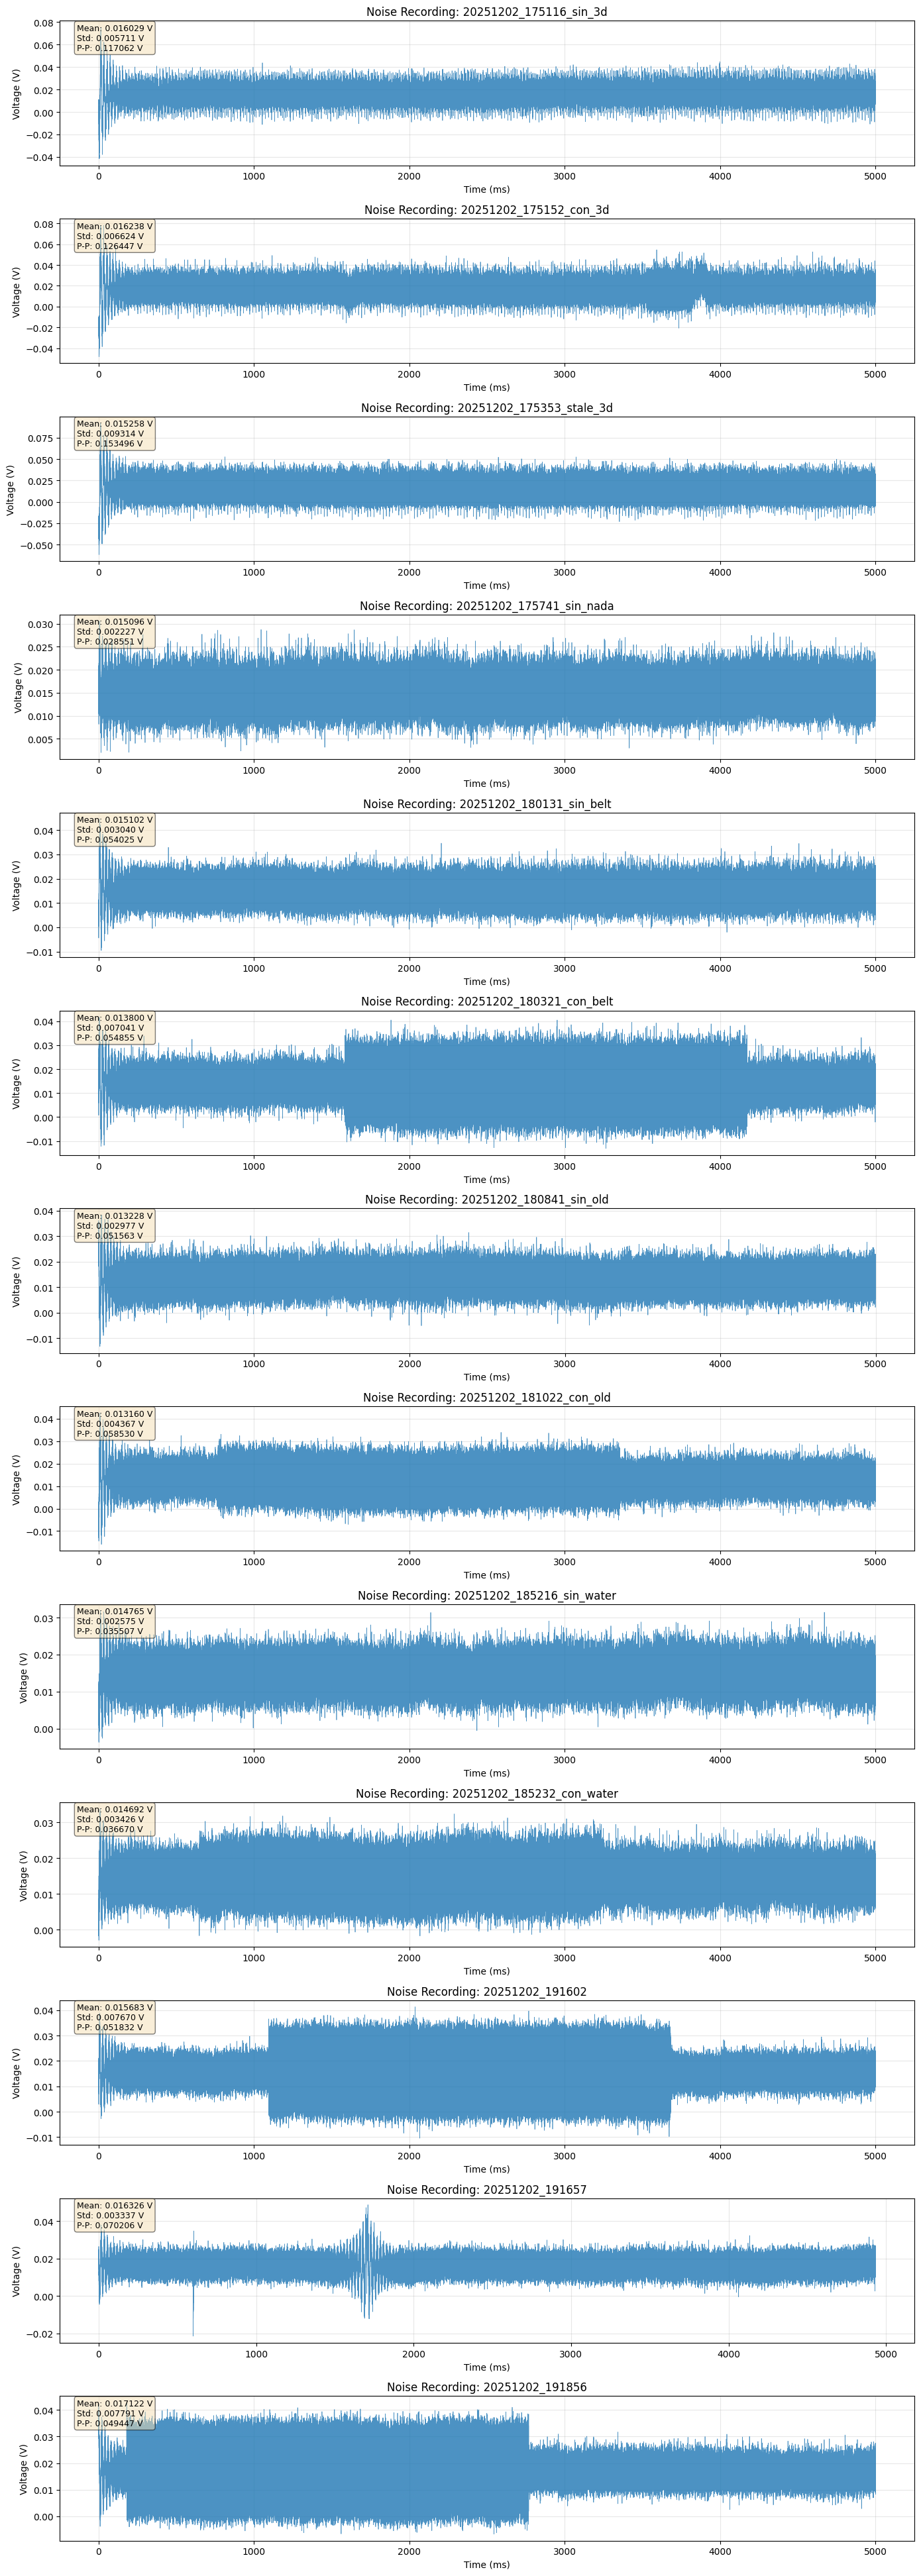

In [13]:
# Plot all measurements (full duration)
fig, axes = plt.subplots(len(noise_data), 1, figsize=(14, 3*len(noise_data)))

if len(noise_data) == 1:
    axes = [axes]

for ax, (label, df) in zip(axes, noise_data.items()):
    ax.plot(df['Timestamp_ms'], df['Voltage_V'], linewidth=0.5, alpha=0.8)
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Voltage (V)')
    ax.set_title(f'Noise Recording: {label}')
    ax.grid(alpha=0.3)
    
    # Add statistics text
    stats = stats_df[stats_df['Measurement'] == label].iloc[0]
    text = f"Mean: {stats['Mean (V)']:.6f} V\nStd: {stats['Std Dev (V)']:.6f} V\nP-P: {stats['Peak-to-Peak (V)']:.6f} V"
    ax.text(0.02, 0.98, text, transform=ax.transAxes, 
            verticalalignment='top', fontsize=9, 
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

## Zoomed View (First 100ms)

Closer look at the noise characteristics.

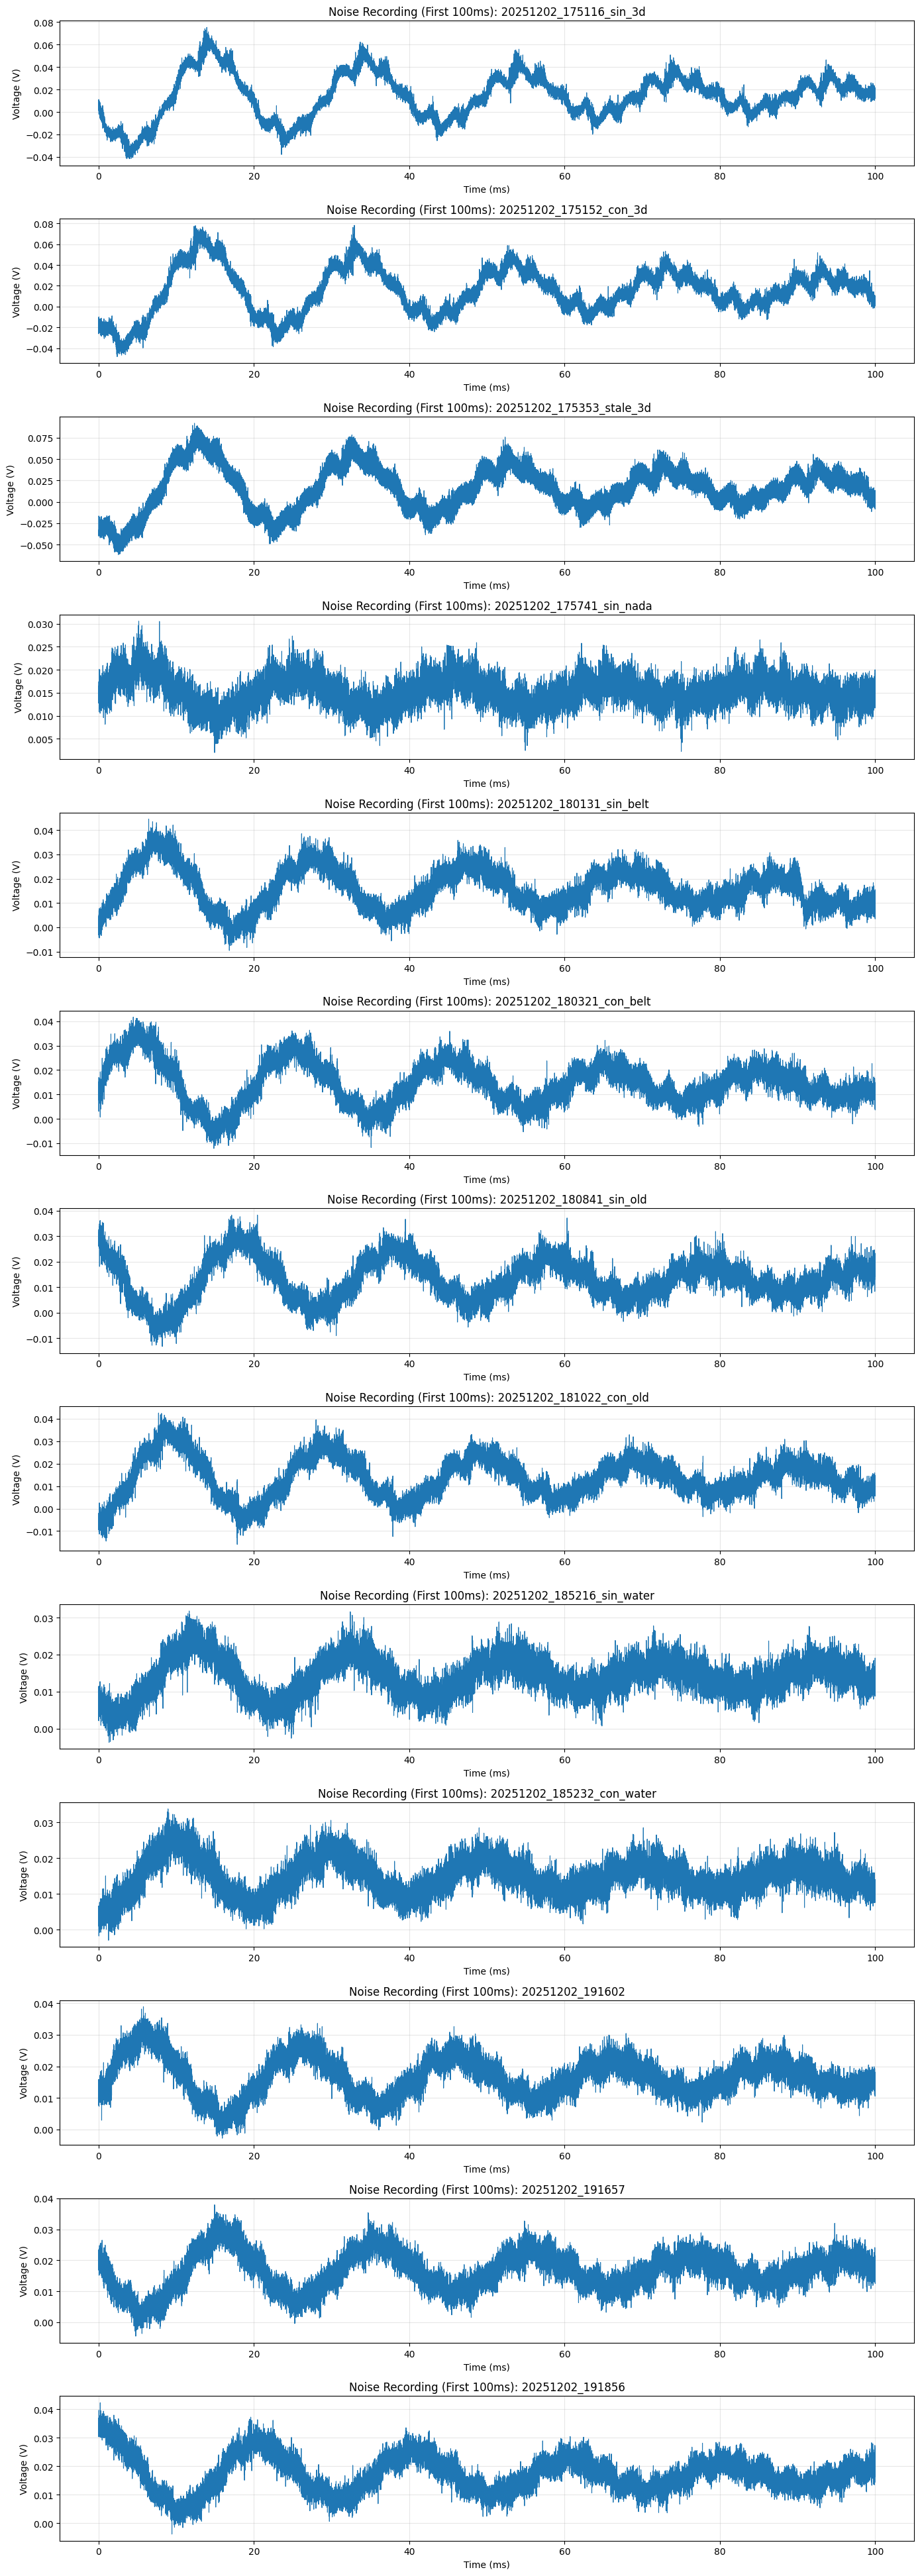

In [14]:
# Plot first 100ms for detailed view
fig, axes = plt.subplots(len(noise_data), 1, figsize=(14, 3*len(noise_data)))

if len(noise_data) == 1:
    axes = [axes]

for ax, (label, df) in zip(axes, noise_data.items()):
    # Plot only first 100ms
    mask = df['Timestamp_ms'] <= 100
    ax.plot(df[mask]['Timestamp_ms'], df[mask]['Voltage_V'], linewidth=0.8)
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Voltage (V)')
    ax.set_title(f'Noise Recording (First 100ms): {label}')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Histogram of Voltage Distribution

Show the distribution of voltage values to assess noise characteristics.

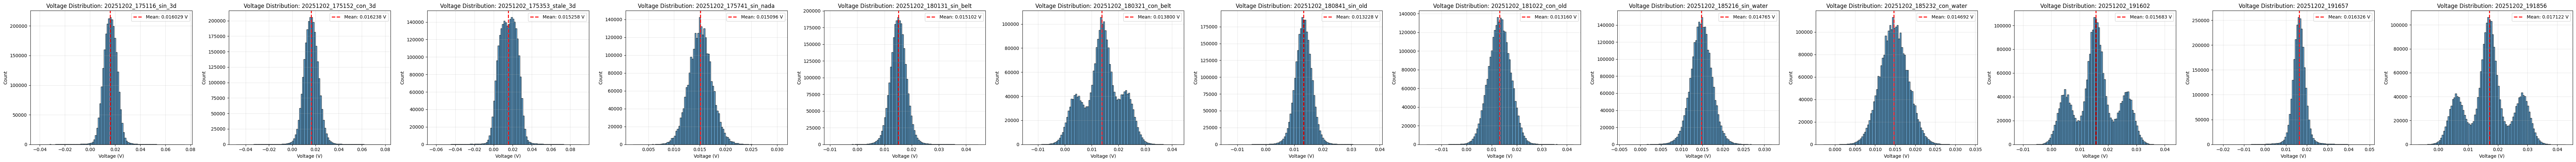

In [20]:
# Histogram for each measurement
fig, axes = plt.subplots(1, len(noise_data), figsize=(6*len(noise_data), 5))

if len(noise_data) == 1:
    axes = [axes]

for ax, (label, df) in zip(axes, noise_data.items()):
    voltage = df['Voltage_V']
    ax.hist(voltage, bins=100, alpha=0.7, edgecolor='black')
    ax.axvline(voltage.mean(), color='r', linestyle='--', linewidth=2, label=f'Mean: {voltage.mean():.6f} V')
    ax.set_xlabel('Voltage (V)')
    ax.set_ylabel('Count')
    ax.set_title(f'Voltage Distribution: {label}')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Frequency Domain Analysis (FFT)

Analyze the frequency content of the noise to identify any periodic interference.

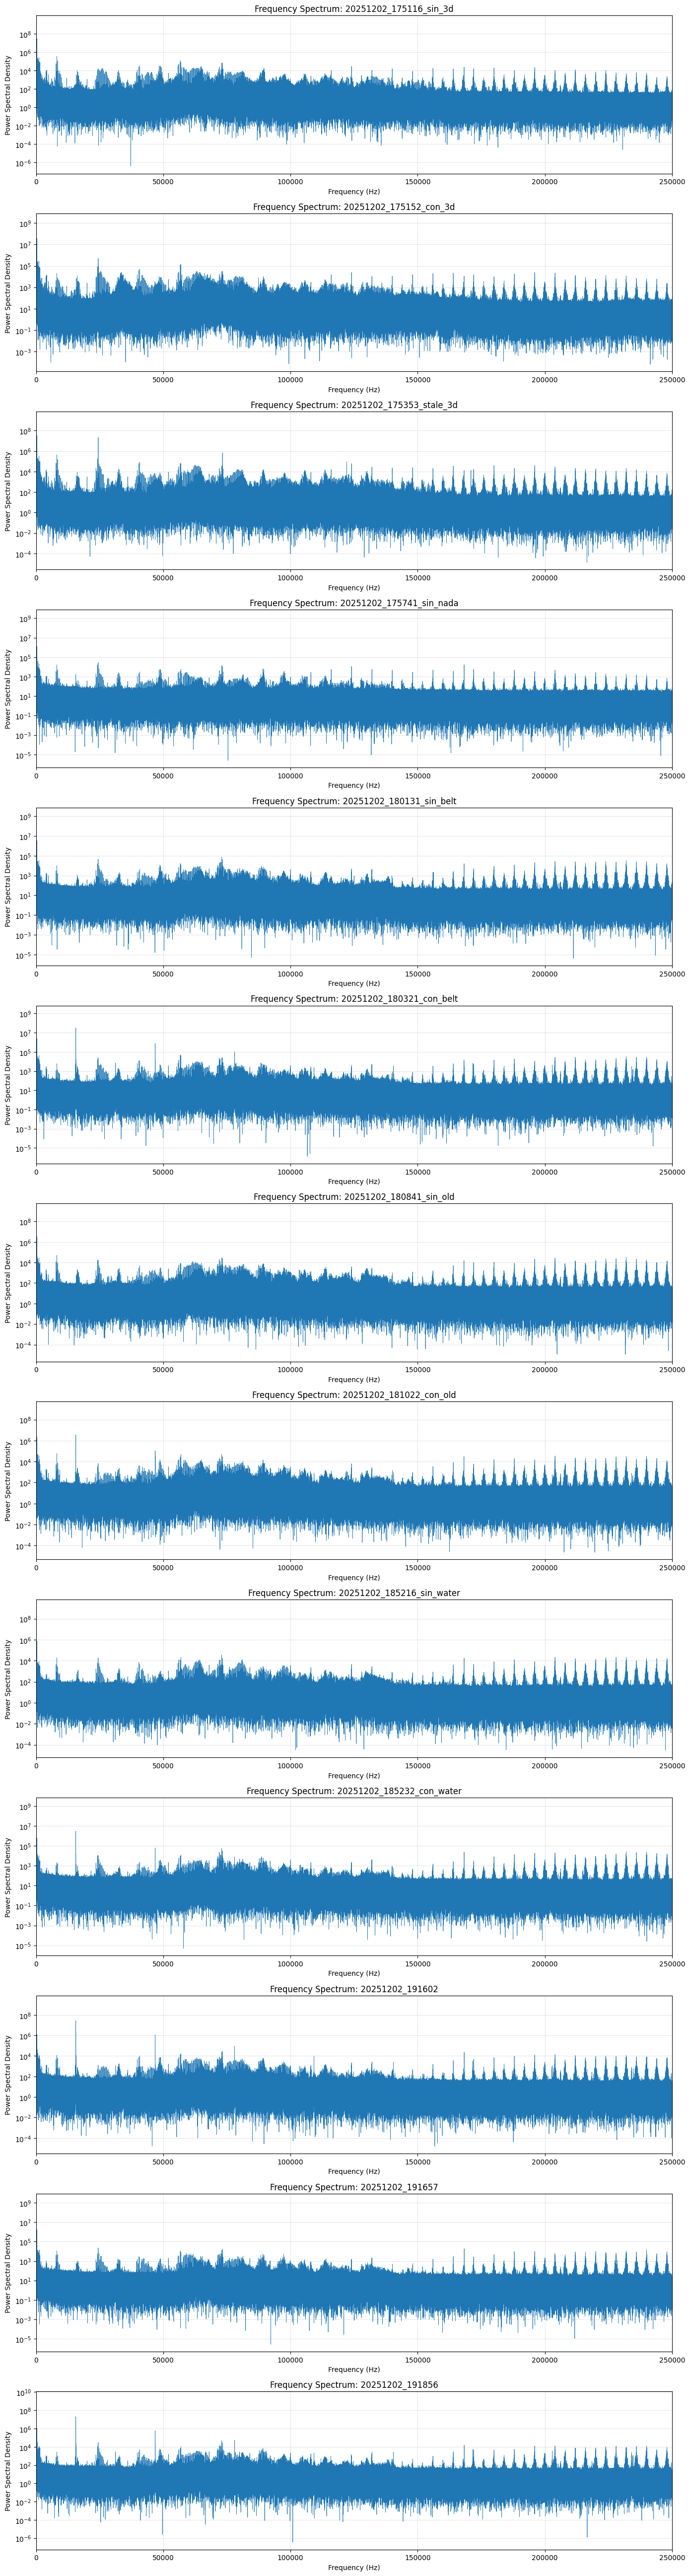

In [16]:
# FFT analysis
fig, axes = plt.subplots(len(noise_data), 1, figsize=(14, 4*len(noise_data)))

if len(noise_data) == 1:
    axes = [axes]

for ax, (label, df) in zip(axes, noise_data.items()):
    voltage = df['Voltage_V'].values
    
    # Calculate sampling frequency from timestamps
    dt = (df['Timestamp_ms'].iloc[1] - df['Timestamp_ms'].iloc[0]) / 1000  # Convert to seconds
    fs = 1 / dt
    
    # Compute FFT
    fft_vals = np.fft.rfft(voltage)
    fft_freq = np.fft.rfftfreq(len(voltage), dt)
    fft_power = np.abs(fft_vals)**2
    
    # Plot power spectrum (log scale)
    ax.semilogy(fft_freq, fft_power, linewidth=0.5)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power Spectral Density')
    ax.set_title(f'Frequency Spectrum: {label}')
    ax.grid(alpha=0.3, which='both')
    ax.set_xlim(0, fs/2)  # Show up to Nyquist frequency

plt.tight_layout()
plt.show()

## Comparison Bar Chart

Compare key noise metrics across all measurements.

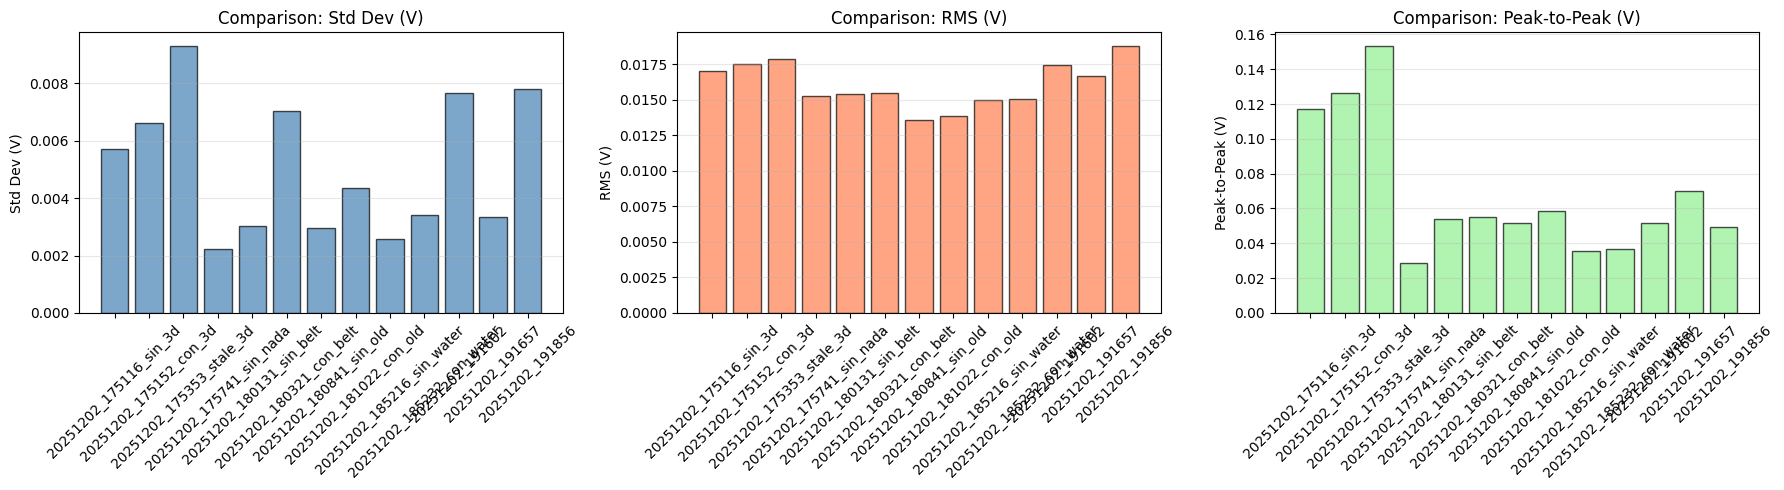

In [17]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['Std Dev (V)', 'RMS (V)', 'Peak-to-Peak (V)']
colors = ['steelblue', 'coral', 'lightgreen']

for ax, metric, color in zip(axes, metrics, colors):
    ax.bar(stats_df['Measurement'], stats_df[metric], color=color, alpha=0.7, edgecolor='black')
    ax.set_ylabel(metric)
    ax.set_title(f'Comparison: {metric}')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Summary Report

Final summary of all measurements.

In [18]:
print("="*80)
print("NOISE MEASUREMENT SUMMARY")
print("="*80)
print(f"\nTotal measurements analyzed: {len(noise_data)}\n")

for _, row in stats_df.iterrows():
    print(f"Measurement: {row['Measurement']}")
    print(f"  Mean:         {row['Mean (V)']:.6f} V")
    print(f"  Std Dev:      {row['Std Dev (V)']:.6f} V")
    print(f"  RMS:          {row['RMS (V)']:.6f} V")
    print(f"  Peak-to-Peak: {row['Peak-to-Peak (V)']:.6f} V")
    print(f"  Range:        [{row['Min (V)']:.6f}, {row['Max (V)']:.6f}] V")
    print()

print("="*80)

NOISE MEASUREMENT SUMMARY

Total measurements analyzed: 13

Measurement: 20251202_175116_sin_3d
  Mean:         0.016029 V
  Std Dev:      0.005711 V
  RMS:          0.017016 V
  Peak-to-Peak: 0.117062 V
  Range:        [-0.041665, 0.075397] V

Measurement: 20251202_175152_con_3d
  Mean:         0.016238 V
  Std Dev:      0.006624 V
  RMS:          0.017537 V
  Peak-to-Peak: 0.126447 V
  Range:        [-0.048222, 0.078225] V

Measurement: 20251202_175353_stale_3d
  Mean:         0.015258 V
  Std Dev:      0.009314 V
  RMS:          0.017876 V
  Peak-to-Peak: 0.153496 V
  Range:        [-0.061661, 0.091834] V

Measurement: 20251202_175741_sin_nada
  Mean:         0.015096 V
  Std Dev:      0.002227 V
  RMS:          0.015259 V
  Peak-to-Peak: 0.028551 V
  Range:        [0.002006, 0.030557] V

Measurement: 20251202_180131_sin_belt
  Mean:         0.015102 V
  Std Dev:      0.003040 V
  RMS:          0.015405 V
  Peak-to-Peak: 0.054025 V
  Range:        [-0.009544, 0.044482] V

Measuremen